# 01 - Exploring the CSI with signal processing

Goal: look at the physics-motivated representations from `src/dsp.py` and check,
**before any deep learning**, which of them change with headcount *and* stay similar across rooms.

Multipath model: $H(f,t) = H_{static}(f) + H_{dynamic}(f,t)$ - walls/furniture are static, people are (mostly) dynamic.

In [ ]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data, dsp

lab = data.load_index("labeled")
unl = data.load_index("unlabeled")
pd.crosstab(lab.layout, lab.headcount)

headcount,0,1,2,3,4
layout,,,,,
a,1,2,3,3,3
b,1,0,0,0,0
c,0,2,3,3,4
e,2,1,0,0,0
g,7,10,0,0,0
unknown,0,3,0,0,0


Unlabelled traces per layout. **None of these layouts appear in the labelled set**, so the test rooms are probably among them.

In [ ]:
unl.layout.value_counts()

layout
u          55
v          47
i          17
h          14
d           8
unknown     5
j           4
Name: count, dtype: int64

## 1. Per-trace summary numbers
For every labelled trace, take 5 windows of 600 frames (like test samples) and compute simple physical quantities:
- `dyn_ratio`: energy of the moving part / energy of the static part
- `eig1`, `eig3`: share of the dynamic variance in the top 1 / top 3 eigen-directions (concentrated = one thing moving)
- ATI timing statistics

In [ ]:
rows = []
for _, r in lab.iterrows():
    csi, ati = data.load_trace(r.identifier)
    csi = dsp.normalize_gain(dsp.clean(csi))
    for s, w, a in data.windows(csi, ati, step=2400):
        ev = dsp.covariance_eigenvalues(w)
        rows.append({"id": r.identifier, "layout": r.layout, "headcount": r.headcount, "start": s,
                     "dyn_ratio": dsp.dynamic_ratio(w), "eig1": ev[0], "eig3": ev[:3].sum(),
                     **dsp.ati_stats(a)})
summary = pd.DataFrame(rows)
summary.to_csv("../cache/explore_summary.csv", index=False)
summary.groupby(["layout", "headcount"])[["dyn_ratio", "eig1", "ati_median", "ati_gap_frac"]].median()

dyn_ratio      eig1   ati_median  ati_gap_frac
layout  headcount                                                
a       0           0.000331  0.310516  5088.000000      0.001669
        1           0.000190  0.334832  5087.000000      0.000000
        2           0.000055  0.353949  5085.000000      0.001669
        3           0.000019  0.401198  5086.000000      0.001669
        4           0.000006  0.403062  5086.000000      0.001669
b       0           0.000007  0.248255  5088.000000      0.000000
c       1           0.000309  0.370066  5087.000000      0.001669
        2           0.000276  0.395935  5083.000000      0.001669
        3           0.000338  0.335793  5084.000000      0.001669
        4           0.000449  0.357123  5085.000000      0.001669
e       0           0.000112  0.604330  5089.637939      0.001669
        1           0.000232  0.293119  5088.050781      0.001669
g       0           0.000024  0.445190  5107.456055      0.013356
        1           0.000026  0.447843  5104.229492      0.010017
unknown 1           0.000035  0.523110  5087.487793      0.000000

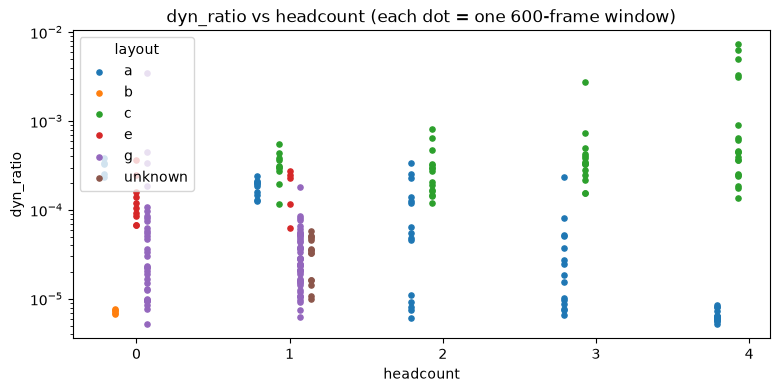

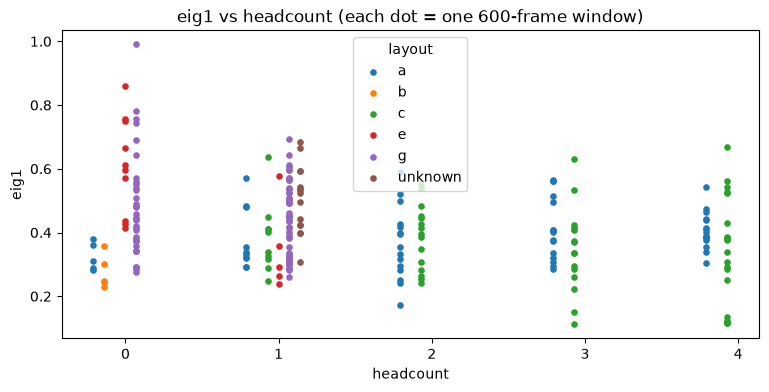

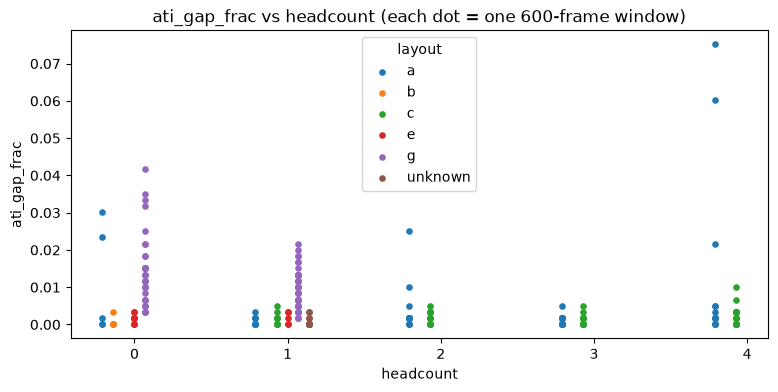

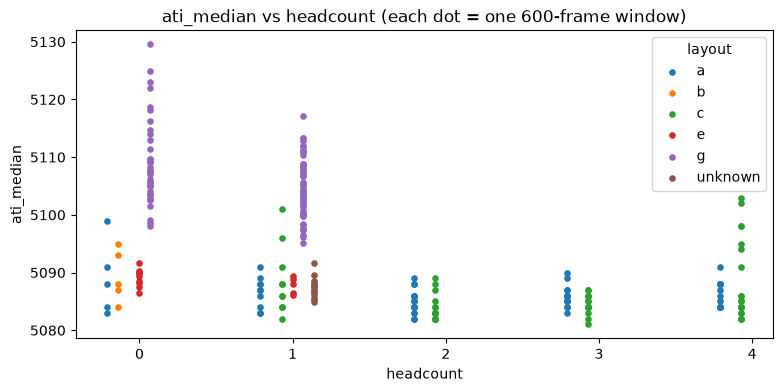

In [ ]:
def strip(col, log=False):
    fig, ax = plt.subplots(figsize=(9, 4))
    layouts = sorted(summary.layout.unique())
    for i, L in enumerate(layouts):
        d = summary[summary.layout == L]
        ax.scatter(d.headcount + (i - len(layouts) / 2) * 0.07, d[col], s=14, label=L)
    if log: ax.set_yscale("log")
    ax.set_xlabel("headcount"); ax.set_ylabel(col); ax.set_xticks(range(5)); ax.legend(title="layout")
    ax.set_title(f"{col} vs headcount (each dot = one 600-frame window)")
    plt.show()

strip("dyn_ratio", log=True)
strip("eig1")
strip("ati_gap_frac")
strip("ati_median")

## 2. What a window looks like: amplitude vs complex dynamic part
Rows: headcount 0..4 in room **a**. Left: amplitude after removing its time-mean (what the old CNN saw).
Right: magnitude of the complex dynamic part $|H - \bar H|$.

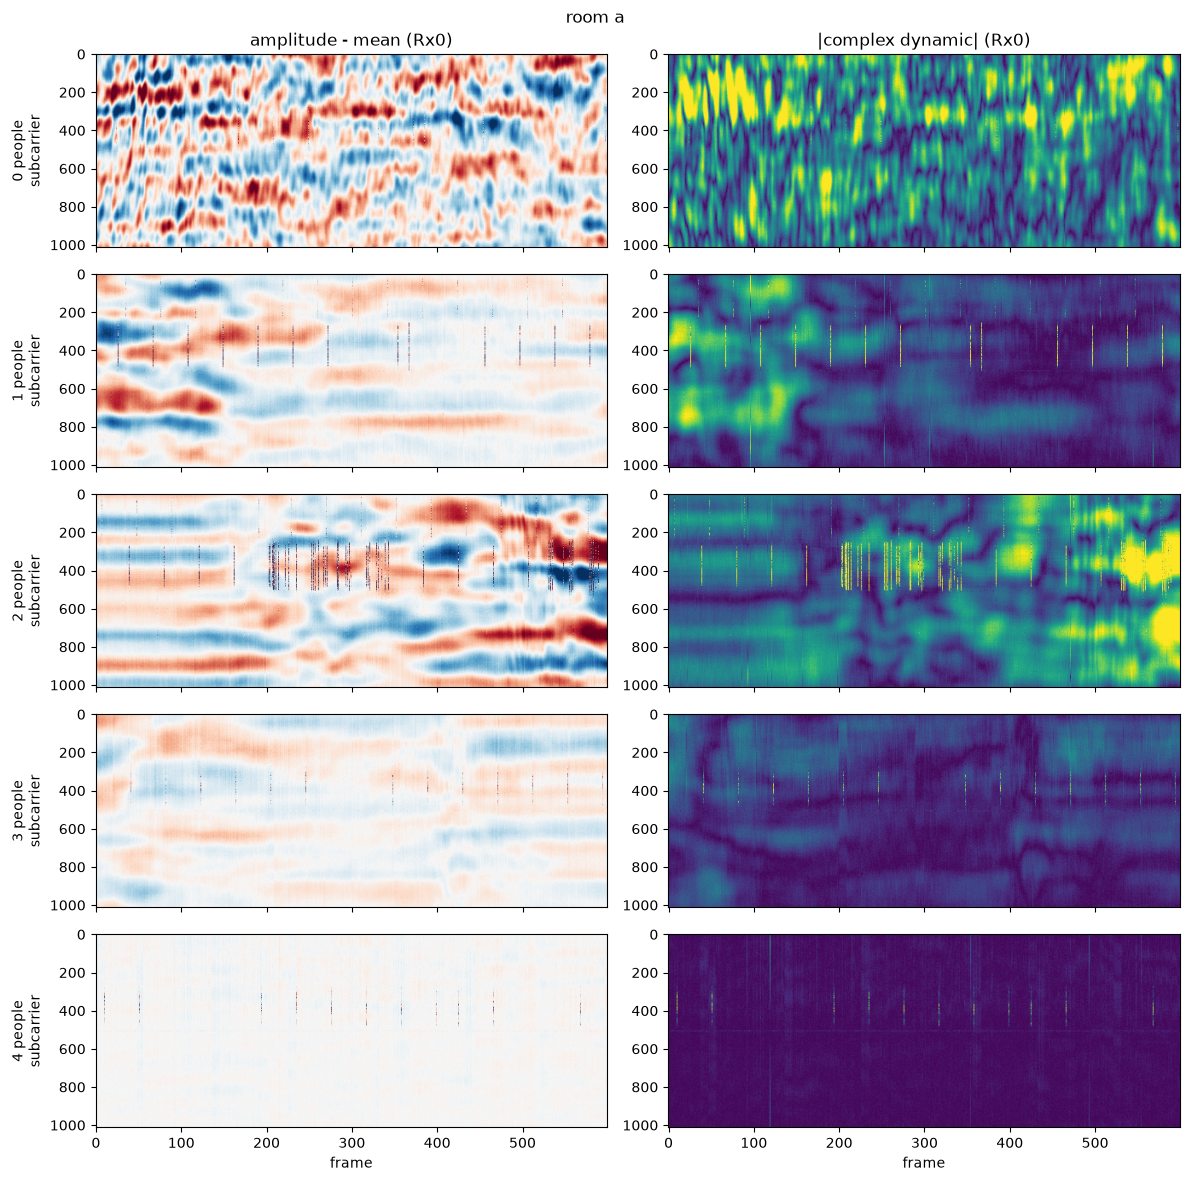

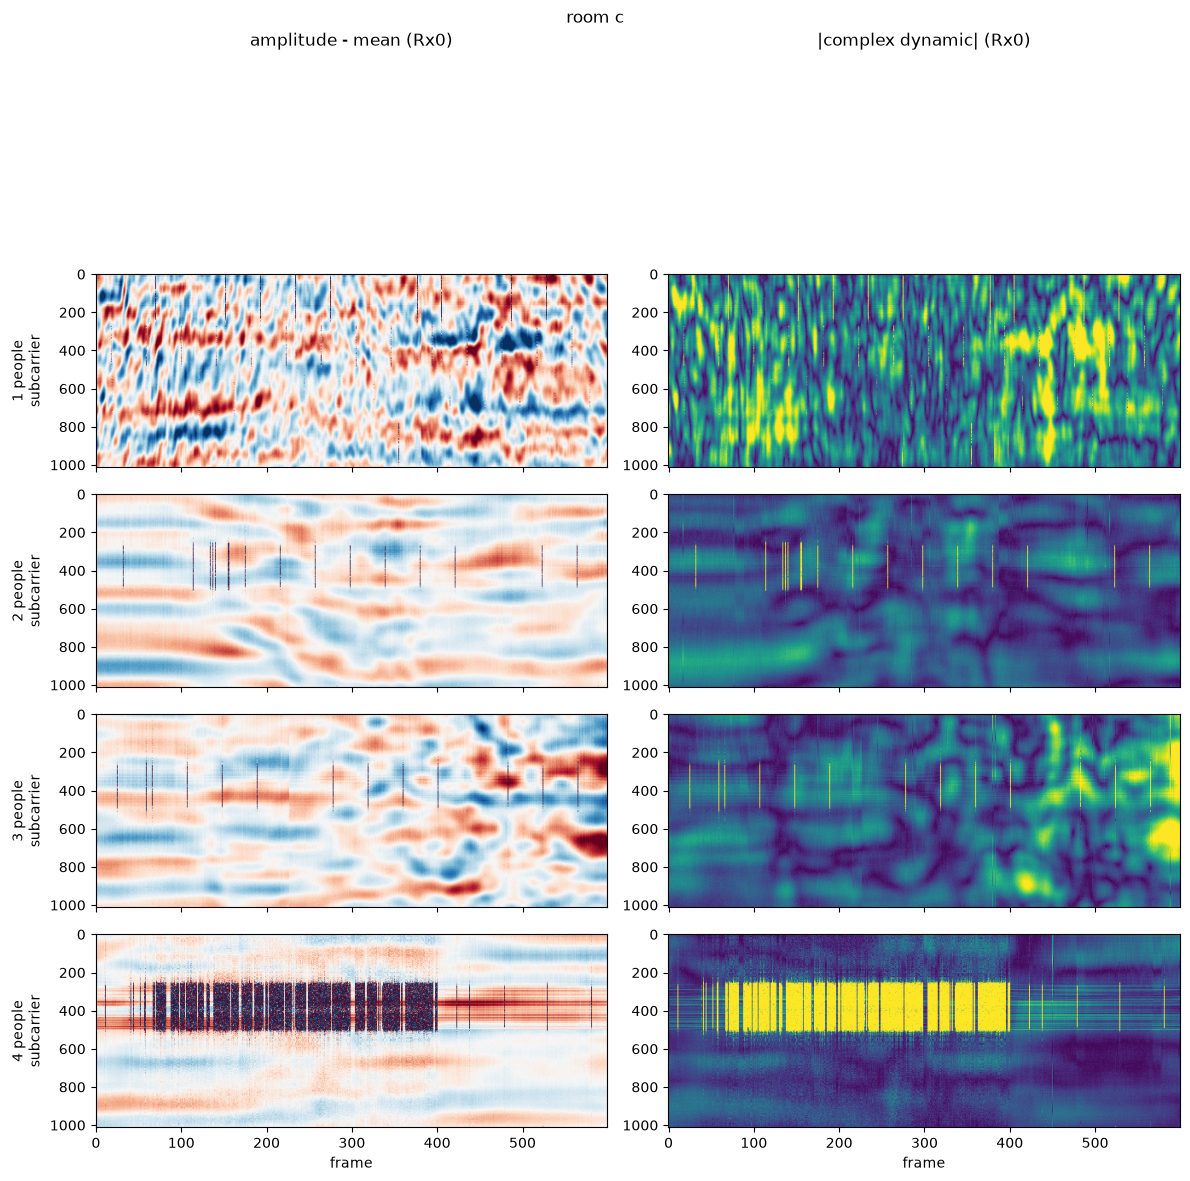

In [ ]:
def first_trace(layout, hc):
    d = lab[(lab.layout == layout) & (lab.headcount == hc)]
    return None if d.empty else d.iloc[0].identifier

def show_room(layout):
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True)
    for hc in range(5):
        tid = first_trace(layout, hc)
        if tid is None:
            axes[hc, 0].set_title(f"{hc} people: none"); axes[hc, 0].axis("off"); axes[hc, 1].axis("off"); continue
        csi, _ = data.load_trace(tid)
        w = dsp.normalize_gain(dsp.clean(csi[:600]))
        amp = np.abs(w[:, 0]); amp = amp - amp.mean(0)
        _, dyn = dsp.split_static_dynamic(w)
        axes[hc, 0].imshow(amp.T, aspect="auto", cmap="RdBu", vmin=-0.05, vmax=0.05)
        axes[hc, 1].imshow(np.abs(dyn[:, 0]).T, aspect="auto", cmap="viridis", vmin=0, vmax=0.05)
        axes[hc, 0].set_ylabel(f"{hc} people\nsubcarrier")
    axes[0, 0].set_title("amplitude - mean (Rx0)"); axes[0, 1].set_title("|complex dynamic| (Rx0)")
    axes[-1, 0].set_xlabel("frame"); axes[-1, 1].set_xlabel("frame")
    plt.suptitle(f"room {layout}"); plt.tight_layout(); plt.show()

show_room("a")
show_room("c")

## 3. Doppler spectrum
Power of the dynamic part vs Doppler frequency. Moving bodies spread energy away from 0 Hz.
Averaged over the 5 windows of every trace with the same (room, headcount).

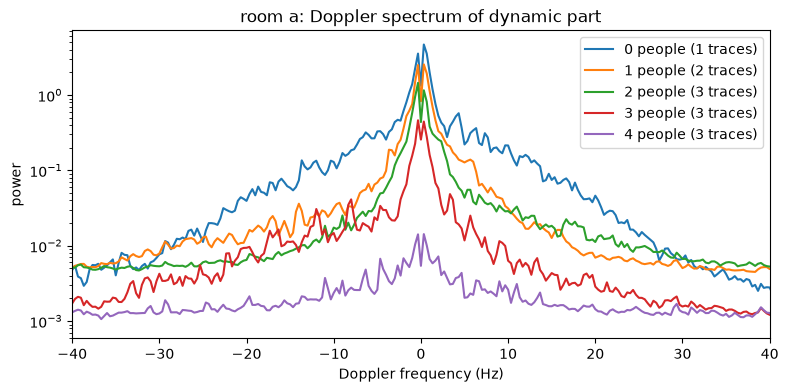

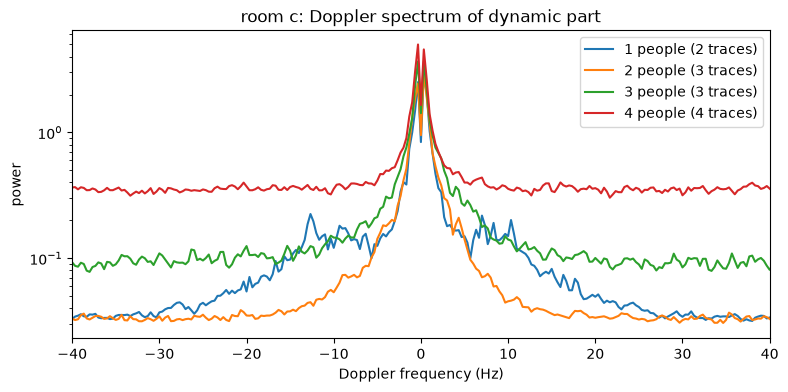

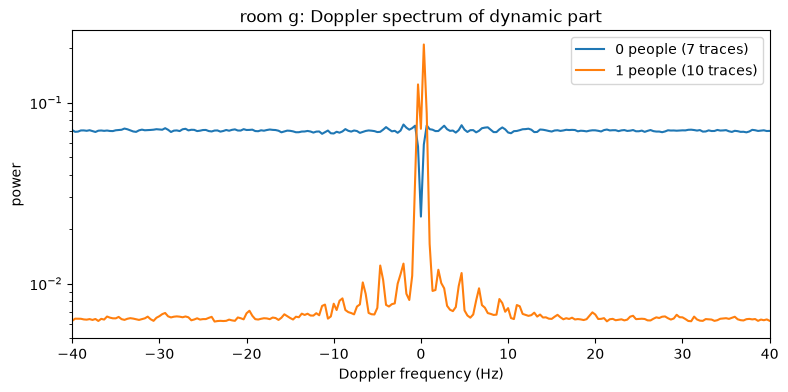

In [ ]:
def doppler_by_headcount(layout):
    plt.figure(figsize=(9, 4))
    for hc in range(5):
        ids = lab[(lab.layout == layout) & (lab.headcount == hc)].identifier
        specs = []
        for tid in ids:
            csi, _ = data.load_trace(tid)
            csi = dsp.normalize_gain(dsp.clean(csi))
            for s, w, _ in data.windows(csi, np.zeros(len(csi)), step=2400):
                f, p = dsp.doppler_spectrum(w)
                specs.append(p)
        if specs:
            plt.semilogy(f, np.mean(specs, 0), label=f"{hc} people ({len(ids)} traces)")
    plt.xlim(-40, 40); plt.xlabel("Doppler frequency (Hz)"); plt.ylabel("power")
    plt.title(f"room {layout}: Doppler spectrum of dynamic part"); plt.legend(); plt.show()

for L in ["a", "c", "g"]:
    doppler_by_headcount(L)

## 4. Doppler spectrograms (time x Doppler 'image') - room a, one trace per headcount

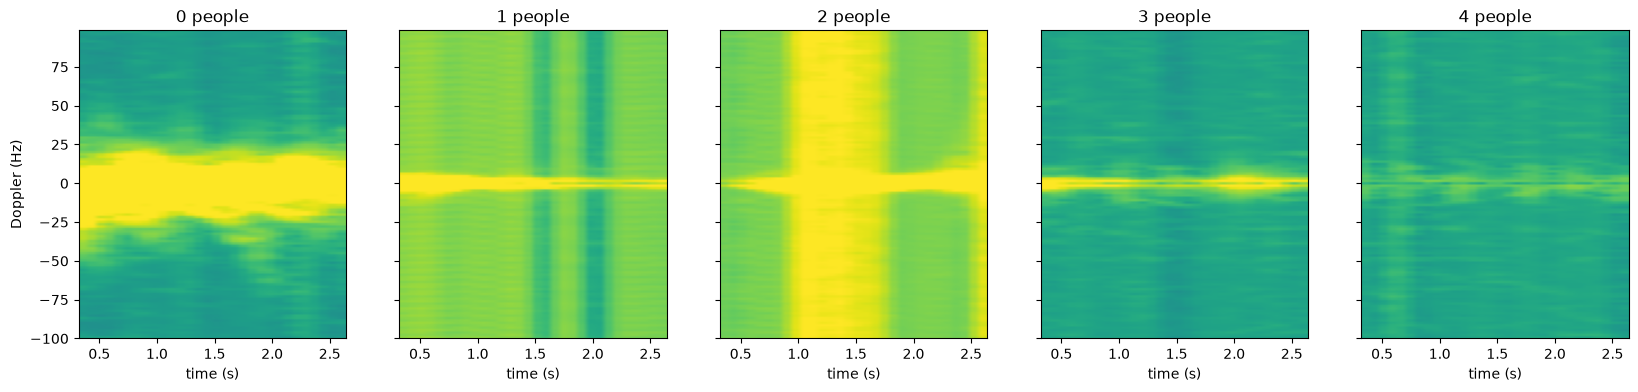

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for hc in range(5):
    tid = first_trace("a", hc)
    csi, _ = data.load_trace(tid)
    f, t, P = dsp.doppler_spectrogram(dsp.normalize_gain(dsp.clean(csi[:600])))
    axes[hc].imshow(10 * np.log10(P.T + 1e-12), aspect="auto", origin="lower",
                    extent=[t[0], t[-1], f[0], f[-1]], vmin=-60, vmax=-20)
    axes[hc].set_title(f"{hc} people"); axes[hc].set_xlabel("time (s)")
axes[0].set_ylabel("Doppler (Hz)"); plt.show()

## 5. The static part: room fingerprint vs headcount
Cosine similarity between the static amplitude profiles (mean over time, per Rx and subcarrier) of all labelled traces,
sorted by room then headcount. Bright blocks along the diagonal = the static part identifies the **room**.
Inside a room block, does it also change with headcount?

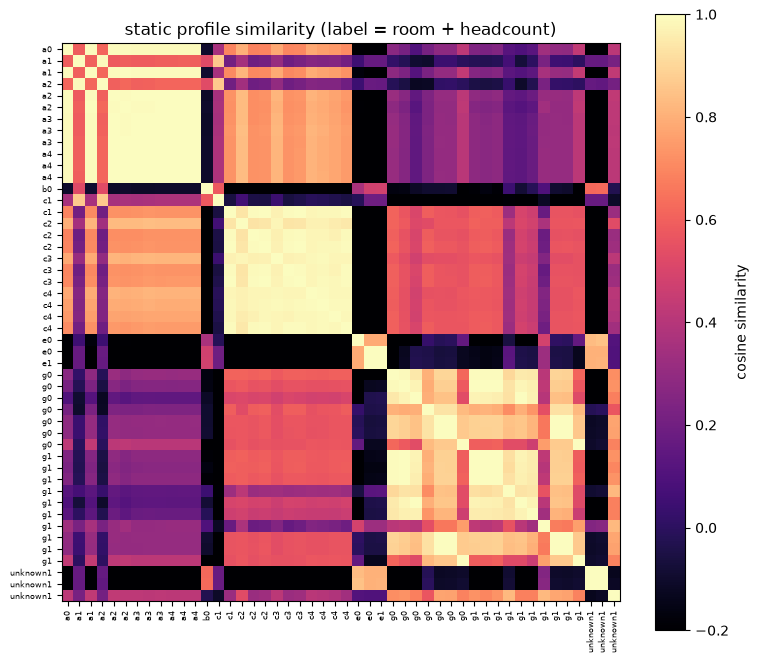

In [ ]:
order = lab.sort_values(["layout", "headcount"]).reset_index(drop=True)
profiles = []
for tid in order.identifier:
    csi, _ = data.load_trace(tid)
    w = dsp.normalize_gain(dsp.clean(csi[:600]))
    p = np.abs(w).mean(0).ravel()
    profiles.append((p - p.mean()) / p.std())
P = np.array(profiles)
sim = P @ P.T / P.shape[1]

plt.figure(figsize=(9, 8))
plt.imshow(sim, cmap="magma", vmin=-0.2, vmax=1)
labels = [f"{l}{h}" for l, h in zip(order.layout, order.headcount)]
plt.xticks(range(len(labels)), labels, rotation=90, fontsize=6)
plt.yticks(range(len(labels)), labels, fontsize=6)
plt.colorbar(label="cosine similarity"); plt.title("static profile similarity (label = room + headcount)")
plt.show()

In [ ]:
# Inside rooms a and c: is the static profile closer for equal headcounts than for different ones?
for L in ["a", "c"]:
    idx = np.where(order.layout == L)[0]
    same, diff = [], []
    for i in idx:
        for j in idx:
            if i < j:
                (same if order.headcount[i] == order.headcount[j] else diff).append(sim[i, j])
    print(f"room {L}: mean similarity same headcount {np.mean(same):.3f} | different headcount {np.mean(diff):.3f}")

room a: mean similarity same headcount 0.880 | different headcount 0.875
room c: mean similarity same headcount 0.898 | different headcount 0.790


## 6. Power-delay profile per room (path lengths - expected to be room specific)

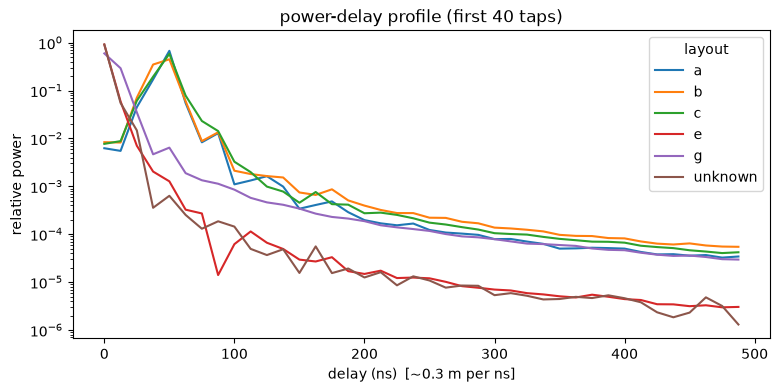

In [ ]:
plt.figure(figsize=(9, 4))
for L in sorted(lab.layout.unique()):
    tid = lab[lab.layout == L].iloc[0].identifier
    csi, _ = data.load_trace(tid)
    d, p = dsp.delay_profile(dsp.normalize_gain(dsp.clean(csi[:600])))
    plt.semilogy(d[:40], p[:40] / p.sum(), label=L)
plt.xlabel("delay (ns)  [~0.3 m per ns]"); plt.ylabel("relative power"); plt.legend(title="layout")
plt.title("power-delay profile (first 40 taps)"); plt.show()


## Findings (2026-10-24)

1. **Motion energy is not monotonic in headcount, and its direction depends on the room.** In room a, `dyn_ratio` and the Doppler width *decrease* from 0 to 4 people (people stood still); in room c they increase. "More people = more motion" does not hold here, so a single motion-energy feature will not transfer to new rooms.
2. **Noise and interference are tied to the recording session, not to people.** In room g the 0-person windows have a ~10x higher flat noise floor than the 1-person ones. One 4-person trace in room c has a large burst in subcarriers ~250-500. The short vertical spikes sit in one 20 MHz sub-band (a different one per room: neighbouring WiFi networks). Every trace has one label, so a model can learn "this noise pattern = this label" - a shortcut that fails on new rooms. Spikes need to be cleaned or made irrelevant (robust statistics, sub-band dropout augmentation).
3. **The static profile identifies the room almost perfectly** (bright diagonal blocks), and even sub-sessions inside room g. Inside room a it carries no headcount information (similarity 0.880 same headcount vs 0.875 different); in room c only a little (0.898 vs 0.790). Raw static amplitudes should not be fed to the model.
4. Static profiles of different rooms are partly similar (a vs c ~0.7): part of the "static" shape is the identical router hardware's frequency response, not the room.
5. The raw phase is already stable over time (std ~0.002 rad on a still channel): hardware offsets look corrected, so complex-valued processing (static removal, Doppler) works directly.
6. ATI timing and the top-eigenvalue share show no clear headcount trend; ATI mostly reflects how busy the room's channel is (g is busier).
